# Book Mood Reader

## Project Overview

Book Mood Reader is a project about connecting books and music through emotions. The idea is to use a book description to predict the atmosphere of the story and return a list of songs with similar feelings.

A book can feel romantic, intense, mysterious or sad at the same time. A song can also express more than one emotion. Instead of choosing one mood for a whole book or song, this project uses a shared set of **25 emotion labels**.

The system has two connected classification pipelines. The first learns from book descriptions. The second learns from numerical features extracted from song audio. Their outputs are compared so that songs matching the book's stronger emotions receive higher matching scores.

The final output is a **ranked list of songs**, including their titles, artists and matching scores. This is a small learning project: the aim is to demonstrate the process and explain the results, rather than create a perfectly accurate recommendation system.

## Objective

The main goal is to explore whether simple classification models can predict emotions from book descriptions and song audio, then use those emotions to recommend music.

The project focuses on:

- Preparing the book and song datasets with consistent emotion names.
- Checking missing values, duplicates and data quality.
- Using visualizations to understand emotion distributions and relationships.
- Turning text and audio into numerical features.
- Comparing two classifiers for each dataset using training, validation and testing.
- Connecting the predicted emotions through a simple weighted matching rule.

## Central Research Question

**How can a book description be used to predict its emotions and recommend songs with matching feelings?**

## Analytical Approach

This project is a **multi-label classification problem with a ranking-based output**. Multi-label means that several emotion labels can apply to the same example.

For books, the questionnaire records strengths from 1 to 5. I preserve those original ratings. For classification, I create a separate target for each emotion:

- **Strongly present (1):** the original rating is 4 or 5.
- **Not strongly present (0):** the original rating is 1, 2 or 3.

This threshold follows the questionnaire meaning of 4: strongly present. A target of 0 does not mean the emotion is completely absent. The threshold is a fixed project choice, not something selected using test results.

For songs, the classifier predicts whether each emotion was selected in the song table. Both pipelines use the same emotion names, although the book ratings and song annotations were collected differently.

I use **TF-IDF** to represent book descriptions and **Librosa** to extract four audio features. The book classifiers are **One-vs-Rest Logistic Regression** and **Linear SVM**. The song classifiers are **One-vs-Rest Logistic Regression** and **Random Forest**. Logistic Regression is the starting baseline; despite its name, it is a classification model.

The classifiers are compared using validation results before testing. The matching step is a normal calculation, not a third machine-learning model. For known books, it can use the original emotion ratings. For a new description, it uses classifier scores, which are not predicted 1–5 questionnaire ratings.

### Evaluation Metrics

The models are evaluated using:

- **Precision:** how many predicted emotion labels are correct.
- **Recall:** how many of the recorded positive labels the model finds.
- **F1:** a balance between precision and recall; validation micro-F1 selects the model.
- **Exact-match accuracy:** whether the whole predicted emotion set is correct.
- **Confusion matrices:** correct and incorrect decisions for one example emotion, Dark.
- **Training versus testing performance:** whether the model performs much better on examples it has already seen.

Micro scores combine label decisions before calculating the measure. They are useful here because each example has several emotion labels. Matching scores are not treated as playlist accuracy: that would require independent listener judgments.

## Dataset Description

The project uses two datasets that remain separate during training:

| Dataset | Size | Main information |
|---|---|---|
| Books | 15 books, 29 source columns | Title, author, genre, description and 25 emotion ratings |
| Songs | 80 songs, 5 source columns, with audio files | Track ID, title, artist, audio path and selected emotion labels |

I collected the book information through a questionnaire. I used a little AI assistance to correct and standardize emotion column names. For the music, I researched songs, downloaded the recordings and created the song table. The existing song labels include AI-assisted suggestions and were approved for this exploratory classification experiment. They still reflect subjective judgments rather than verified emotional truth.

Book descriptions are the only book-model input. Title, author and genre help with inspection and EDA. For music, the model uses measurements extracted from the audio, not the title or artist name. The 25 common emotion names connect the outputs later.

## Methodology & Workflow

This project follows a simple workflow:

1. **Planning:** define the description-to-playlist idea, the shared labels and the classification tasks.
2. **Preparation:** collect and inspect both datasets, clean their formats, explore the data and prepare numerical features.
3. **Modeling:** split the data into training, validation and testing, fit two classifiers per dataset, and choose using validation F1.
4. **Evaluation:** compare training/testing performance, inspect mistakes, demonstrate matching and explain limitations.

The target split is **70% training, 10% validation and 20% testing**. This is exactly 56/8/16 for songs. For 15 books, rounding gives 10/2/3 because an example cannot be divided. Learned vocabulary and scaling statistics come only from training data.

## Notebook Goals

In this notebook, I will:

- Display and inspect both datasets.
- Check data types, null values, duplicates and audio paths.
- Explain how the original ratings become classification targets.
- Explore emotion patterns, genres, durations and correlations.
- Explain and prepare TF-IDF and simple audio features.
- Train and compare the agreed classifier pairs.
- Demonstrate the weighted song list and evaluate what the results do and do not show.

### Repository version
This is the final edited classification notebook. It can use the supplied audio-feature cache when recordings are not available locally. In that mode, audio-file quality is not revalidated. The notebook demonstrates mood-based song ranking; the separate presentation app currently uses a fixed playlist with calculated match scores.


## Data Source and Data Cleaning Process

### Data Source

The book source is my questionnaire dataset, supplied as **`book_moods_clean_ratings.csv`**. Readers provided book information and descriptions and rated 25 emotions. The rating scale is 1 = very weakly present, 2 = slightly present, 3 = moderately present, 4 = strongly present and 5 = dominant/very strongly present.

The song source is my latest five-column **`songs.xlsx`** table and the downloaded MP3 files. The original ZIP contained 82 MP3 entries, including two empty downloads. Those empty files were excluded when the current 80-song table was created. The notebook checks the files in that current table.

I chose this collection method because the project needs books and songs described using the same emotion vocabulary. Collecting the data myself makes the connection possible, but the small convenience sample and subjective labels limit the conclusions.

### Data Preparation and Cleaning Process

#### Step 1 – Organizing the Two Datasets

I keep the book table and song table separate because they contain different inputs. Each song has an audio path and track ID. The two datasets will be connected through emotion names, rather than by merging unrelated book and song rows.

#### Step 2 – Standardizing Emotion Columns and Labels

Book emotion names were standardized with some AI assistance, including **Peacful → Peaceful** and **Melanchonic → Melancholic**. Song lists can use commas or semicolons, so the code converts them into one consistent format and checks them against the book vocabulary.

#### Step 3 – Checking Values and Duplicates

I inspect null values and duplicates, trim extra spaces and convert book ratings to numbers. A book needs a description and valid ratings between 1 and 5. A song needs an audio path and at least one selected label. Missing emotion ratings are not replaced with invented values.

#### Step 4 – Checking the Audio Files

I check that every listed audio file exists and is nonempty. Duration information helps inspect unusual files. Some recordings are live, edited or music-video versions, so a readable file is not automatically a consistent or perfectly identified training example.

#### Step 5 – Preparing Model Inputs and Targets

The book ratings are preserved, while a separate strong/not-strong target is created for classification. Descriptions are converted with TF-IDF. Librosa turns a consistent audio excerpt into tempo, energy, brightness and zero-crossing rate. These steps are explained and implemented later in the notebook.

### Final Dataset Overview

The supplied source tables contain **15 books and 80 playable songs**. The following code checks whether additional rows need removing during this run; it does not assume that cleaning must always remove records.

Both datasets share 25 emotion names. Books retain their numerical rating profiles. Songs retain their selected labels and links to the audio. These source values, prepared features and classification targets have different purposes and are kept distinguishable throughout the work.

## Dataset Loading and Initial Inspection

I first load the libraries and the two source files, then display their shapes and first rows. This confirms that the files are readable and shows how the data is organized before cleaning or analysis. The source files stay unchanged; later steps work on copies.

In [1]:
# Paths let the notebook use the files inside the extracted project folder.
from pathlib import Path
import re
import json

# These libraries handle tables, calculations, and charts.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Librosa extracts audio measurements; soundfile reads file information.
import librosa
import soundfile as sf
import joblib
from IPython.display import display

# All prediction models in this notebook are CLASSIFIERS.
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import MultiLabelBinarizer, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.multiclass import OneVsRestClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Reuse a fixed seed so random splits and trees are reproducible.
SEED = 42
# Support launching Jupyter from the repository root or notebooks/ folder.
ROOT = Path.cwd().resolve()
if not (ROOT / 'data/raw').is_dir():
    ROOT = ROOT.parent
if not (ROOT / 'data/raw').is_dir():
    raise FileNotFoundError('Open this notebook from the repository root or notebooks/ folder.')
DATA = ROOT / 'data'
TABLES = ROOT / 'results/tables'
FIGURES = ROOT / 'results/figures'
MODELS = ROOT / 'models'
for folder in [TABLES, FIGURES, MODELS]:
    folder.mkdir(parents=True, exist_ok=True)

# Apply the same chart size and save each figure before displaying it.
plt.rcParams.update({'figure.figsize': (10, 5), 'figure.dpi': 110})
def finish_chart(filename):
    plt.tight_layout()
    plt.savefig(FIGURES / filename, bbox_inches='tight')
    plt.show()

In [2]:
# Read the two original sources and preview their structure.
books_raw = pd.read_csv(DATA / 'raw/book_moods_clean_ratings.csv')
songs_raw = pd.read_excel(DATA / 'raw/songs.xlsx', sheet_name='Songs')

print('Book dataset shape:', books_raw.shape)
display(books_raw.head())
print('Song dataset shape:', songs_raw.shape)
display(songs_raw.head())

# Keep the book mood column order for both classifiers and matching.
MOODS = list(books_raw.columns[4:])
print('The shared emotion labels are:')
print(', '.join(MOODS))

Book dataset shape: (15, 29)


,title,author,genre,description,Intense,Exciting,Chaotic,Playful,Adventurous,Epic,Heartwarming,Disturbing,Emotional,Peaceful,Magical,Hopeful,Mysterious,Melancholic,Cozy,Sad,Nostalgic,Romantic,Lonely,Tragic,Scary,Dreamy,Angry,Joyful,Dark
0,Promises we meant to keep,Monica Murphy,Romance; Drama; Young Adult,It’s an emotional romance about two young peop...,4,4,3,4,3,4,3,3,4,2,1,4,2,3,2,2,3,4,1,2,1,4,3,3,4
1,Powerless,Lauren Roberts,Fantasy; Romance; Mystery; Adventure; Drama; Y...,"Is a thrilling romantasy about young girl, who...",4,4,2,2,4,4,2,1,4,2,4,3,3,3,2,3,2,4,4,3,3,4,3,3,2
2,Alchemised,SenLinYu,Fantasy; Romance; Drama,The book starts with the end of a war where th...,5,5,4,1,4,4,4,3,5,1,4,5,5,5,2,5,3,5,5,5,5,5,2,1,5
3,Lights out,Navessa Allen,Romance,It’s about a woman that works in healthcare an...,3,5,4,5,1,3,2,3,3,1,1,1,2,1,3,1,1,5,1,1,1,3,3,3,5
4,A Good Girl's Guide to Murder,Holly Jackson,Mystery; Thriller; Crime,A girl decides to investigate a murder for her...,3,3,3,1,2,3,1,2,2,1,1,2,3,2,1,3,1,2,1,3,2,1,3,2,3


Song dataset shape: (80, 5)


,track_id,song_title,artist,audio_file,emotion_labels
0,song_001,dark days,21 Savage ft. Mariah the Scientist,audio/001_21_Savage_ft_Mariah_the_Scientist_da...,Dark; Emotional; Melancholic; Sad; Intense
1,song_002,Darkside,Alan Walker ft. Au/Ra & Tomine Harket,audio/002_Alan_Walker_ft_Au_Ra_Tomine_Harket_D...,Dark; Exciting; Dreamy; Mysterious; Intense
2,song_003,Carry You Home,Alex Warren,audio/003_Alex_Warren_Carry_You_Home.mp3,Romantic; Heartwarming; Hopeful; Emotional; Jo...
3,song_004,Eternity,Alex Warren,audio/004_Alex_Warren_Eternity.mp3,Sad; Emotional; Melancholic; Nostalgic; Lonely
4,song_005,Ordinary,Alex Warren,audio/005_Alex_Warren_Ordinary.mp3,Romantic; Emotional; Heartwarming; Hopeful; Dr...


The shared emotion labels are:
Intense, Exciting, Chaotic, Playful, Adventurous, Epic, Heartwarming, Disturbing, Emotional, Peaceful, Magical, Hopeful, Mysterious, Melancholic, Cozy, Sad, Nostalgic, Romantic, Lonely, Tragic, Scary, Dreamy, Angry, Joyful, Dark


## Data Types and Missing Value Handling

### Book Dataset

I check null values, duplicates and rating types. Text fields are trimmed and ratings are converted into numbers. Records without required descriptions or targets are removed rather than assigned invented targets. The original 1–5 ratings remain available for analysis and known-book matching.

In [3]:
# Show original column types and non-null counts before cleaning.
books_raw.info()

# Inspect missing values before changing any data.
print('Book null values before cleaning:')
display(books_raw.isnull().sum().to_frame('Null values'))
print('Exact duplicate rows:', books_raw.duplicated().sum())

# Correct known column spelling, then work on a copy.
books = books_raw.rename(columns={'Peacful': 'Peaceful', 'Melanchonic': 'Melancholic'}).copy()
MOODS = list(books.columns[4:])
# Trim text and convert target ratings into numerical values.
for column in ['title', 'author', 'genre', 'description']:
    books[column] = books[column].astype('string').str.strip()
for column in MOODS:
    books[column] = pd.to_numeric(books[column], errors='coerce')

# Remove unusable/duplicate records; do not invent missing emotion ratings.
books = books.drop_duplicates()
books = books.dropna(subset=['description'] + MOODS)
books = books[books['description'].str.len() > 0].reset_index(drop=True)
# Check the questionnaire range and save the cleaned copy.
assert books[MOODS].ge(1).all().all() and books[MOODS].le(5).all().all()
assert len(MOODS) == 25
print('Book rows removed:', len(books_raw) - len(books))
print('Book dataset after cleaning:', books.shape)
books.to_csv(DATA / 'books_clean.csv', index=False)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15 entries, 0 to 14
Data columns (total 29 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   title         15 non-null     object
 1   author        15 non-null     object
 2   genre         15 non-null     object
 3   description   15 non-null     object
 4   Intense       15 non-null     int64 
 5   Exciting      15 non-null     int64 
 6   Chaotic       15 non-null     int64 
 7   Playful       15 non-null     int64 
 8   Adventurous   15 non-null     int64 
 9   Epic          15 non-null     int64 
 10  Heartwarming  15 non-null     int64 
 11  Disturbing    15 non-null     int64 
 12  Emotional     15 non-null     int64 
 13  Peaceful      15 non-null     int64 
 14  Magical       15 non-null     int64 
 15  Hopeful       15 non-null     int64 
 16  Mysterious    15 non-null     int64 
 17  Melancholic   15 non-null     int64 
 18  Cozy          15 non-null     int64 
 19  Sad       

,Null values
title,0
author,0
genre,0
description,0
Intense,0
Exciting,0
Chaotic,0
Playful,0
Adventurous,0
Epic,0


Exact duplicate rows: 0
Book rows removed: 0
Book dataset after cleaning: (15, 29)


### Song Dataset

I check missing fields and duplicate title/artist pairs, standardize label separators and verify the shared vocabulary. I also check that each listed audio file exists and contains data. The checks identify whether the supplied table is usable; they do not prove the emotional labels or song versions are correct.

In [4]:
# Show original column types and non-null counts before cleaning.
songs_raw.info()

# Check missing fields and duplicated song identities.
print('Song null values before cleaning:')
display(songs_raw.isnull().sum().to_frame('Null values'))
print('Duplicate title/artist pairs:', songs_raw.duplicated(['song_title', 'artist']).sum())

# Work on a copy and normalize whitespace.
songs = songs_raw.copy()
for column in songs.columns:
    songs[column] = songs[column].astype('string').str.strip()
# Remove records without the required audio path or emotion list.
songs = songs.drop_duplicates(['song_title', 'artist'])
songs = songs.dropna(subset=['audio_file', 'emotion_labels']).reset_index(drop=True)
# Accept commas or semicolons and save the labels in one consistent format.
songs['label_list'] = songs['emotion_labels'].apply(
    lambda text: [label.strip() for label in re.split('[;,]', text) if label.strip()])
songs['emotion_labels'] = songs['label_list'].apply(lambda labels: '; '.join(labels))

# Validate the shared vocabulary and check every audio path.
unknown_labels = {label for labels in songs['label_list'] for label in labels} - set(MOODS)
assert not unknown_labels, f'Unknown emotion labels: {unknown_labels}'
assert songs['track_id'].is_unique
assert songs['label_list'].apply(len).gt(0).all()
# Audio recordings are local-only. The repository includes their cached features.
audio_present = songs['audio_file'].apply(lambda name: (DATA / name).is_file())
if audio_present.all():
    assert songs['audio_file'].apply(lambda name: (DATA / name).stat().st_size > 0).all()
    print('All local audio files are present and non-empty.')
else:
    if not (DATA / 'simple_audio_features.csv').is_file():
        raise FileNotFoundError('Restore the local audio files or the supplied audio-feature cache.')
    print(f'{(~audio_present).sum()} recordings are unavailable locally; using cached features. '
          'Audio file quality cannot be rechecked in this mode.')

print('Song rows removed:', len(songs_raw) - len(songs))
print('Songs ready for the experiment:', len(songs))
songs.drop(columns='label_list').to_csv(DATA / 'songs_clean.csv', index=False)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 80 entries, 0 to 79
Data columns (total 5 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   track_id        80 non-null     object
 1   song_title      80 non-null     object
 2   artist          80 non-null     object
 3   audio_file      80 non-null     object
 4   emotion_labels  80 non-null     object
dtypes: object(5)
memory usage: 3.3+ KB
Song null values before cleaning:


,Null values
track_id,0
song_title,0
artist,0
audio_file,0
emotion_labels,0


Duplicate title/artist pairs: 0
80 recordings are unavailable locally; using cached features. Audio file quality cannot be rechecked in this mode.
Song rows removed: 0
Songs ready for the experiment: 80


## Creating the Emotion Labels

Before modeling, it is important to define exactly what the classifiers predict. For books, a rating of 4 or 5 becomes **strongly present (1)** and a rating below 4 becomes **not strongly present (0)**. The preview below shows this derived target format without overwriting the original ratings.

For songs, the existing emotion list defines selected/not-selected targets. The label matrix is created later for each split. Both tasks are multi-label: several emotion columns can be positive for one record. This is different from selecting one exclusive category for every book or song.

In [5]:
# Create a separate preview of the book classification targets.
# The original numerical ratings in books[MOODS] are not changed.
book_label_preview = (books[MOODS] >= 4).astype(int)

# Display titles alongside the strong/not-strong indicators for the first books.
display(pd.concat([books[['title']], book_label_preview], axis=1).head())

,title,Intense,Exciting,Chaotic,Playful,Adventurous,Epic,Heartwarming,Disturbing,Emotional,Peaceful,Magical,Hopeful,Mysterious,Melancholic,Cozy,Sad,Nostalgic,Romantic,Lonely,Tragic,Scary,Dreamy,Angry,Joyful,Dark
0,Promises we meant to keep,1,1,0,1,0,1,0,0,1,0,0,1,0,0,0,0,0,1,0,0,0,1,0,0,1
1,Powerless,1,1,0,0,1,1,0,0,1,0,1,0,0,0,0,0,0,1,1,0,0,1,0,0,0
2,Alchemised,1,1,1,0,1,1,1,0,1,0,1,1,1,1,0,1,0,1,1,1,1,1,0,0,1
3,Lights out,0,1,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,1
4,A Good Girl's Guide to Murder,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0


## Exploratory Data Analysis (EDA)

With the datasets checked, I explore their distributions and relationships. I want to understand which emotions are common, which genres are represented, how ratings relate, and what the audio collection looks like.

Each visualization has an explanation before the code and a written interpretation afterwards. EDA describes the collected sample; it does not establish that a model can predict the same patterns accurately.

### Average Book Emotion Ratings

This chart shows average strength for each emotion using the original questionnaire ratings. It helps identify uneven emotion coverage before those ratings are used to create classification targets. Several emotions can apply to the same book.

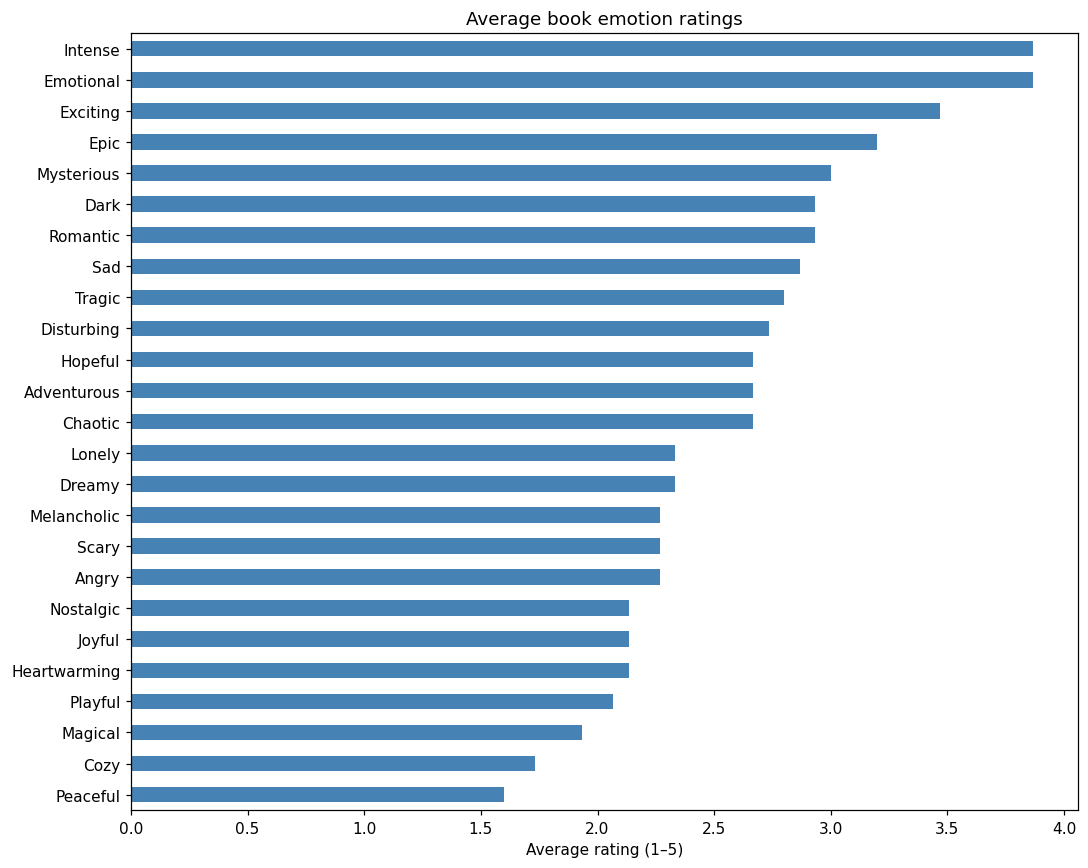

In [6]:
# Average the original 1–5 ratings; this EDA does not change the classification targets.
average_moods = books[MOODS].mean().sort_values()
# Show one horizontal bar for each emotion.
average_moods.plot.barh(color='steelblue', figsize=(10, 8))
plt.xlabel('Average rating (1–5)')
plt.title('Average book emotion ratings')
finish_chart('book_average_emotions.png')

### Interpretation and Conclusion

The highest average ratings are for **Emotional, Intense, Exciting**, while **Peaceful, Cozy, Magical** have the lowest averages. The collection therefore contains more evidence for some emotions than others. After ratings are converted to strong/not-strong targets, common emotions may be easier to learn, while rare strong emotions may be missed. The chart describes this questionnaire sample; it does not prove that a high mean makes an emotion easy to predict from text.

### Book Genre Distribution

A book can have more than one genre. I count each genre separately to see what kinds of books the questionnaire contains. Genre is used for EDA only, not as an input to the book model.

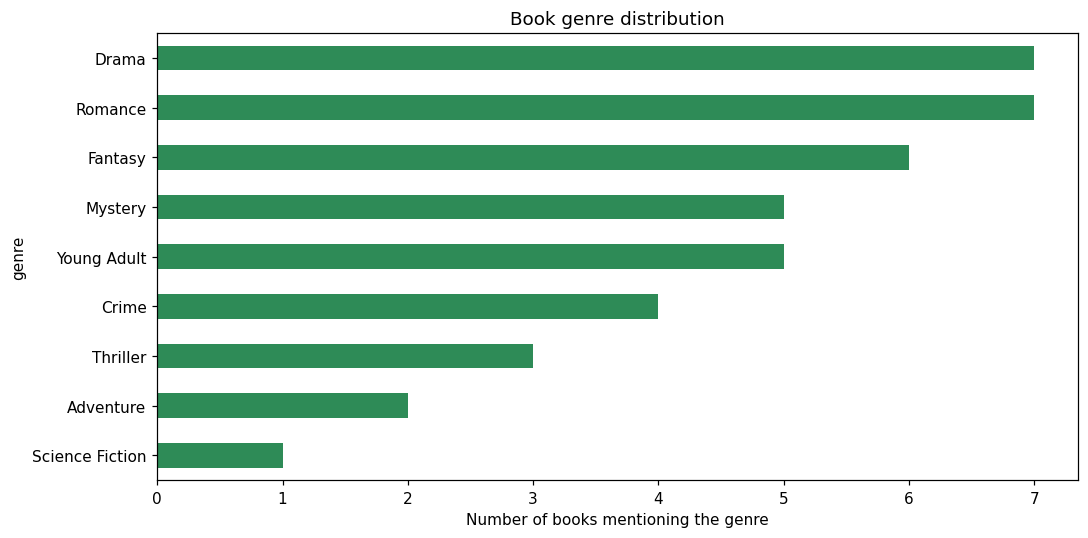

In [7]:
# A book can have several semicolon-separated genres; count them separately.
genres = books['genre'].str.replace('Scinece Fiction', 'Science Fiction', regex=False).str.split(r';\s*')
genre_counts = genres.explode().str.strip().value_counts()
# Plot those counts rather than treating every genre combination as a new genre.
genre_counts.sort_values().plot.barh(color='seagreen')
plt.xlabel('Number of books mentioning the genre')
plt.title('Book genre distribution')
finish_chart('book_genres.png')

### Interpretation and Conclusion

**Romance** is the most frequent genre, appearing in **7 of 15 books**. This means the text examples are concentrated in particular types of stories. Even though genre is not a model input, genre-related words and themes occur in the descriptions, so the model may learn patterns that transfer poorly to underrepresented genres. Collecting more varied books would improve coverage.

### Correlation Between Book Emotions

This heatmap compares eight emotions to keep the chart readable. A positive correlation means two ratings tend to rise together; a negative one means they tend to move in opposite directions. Correlation does not mean one feeling causes another, and results from 15 books can change easily.

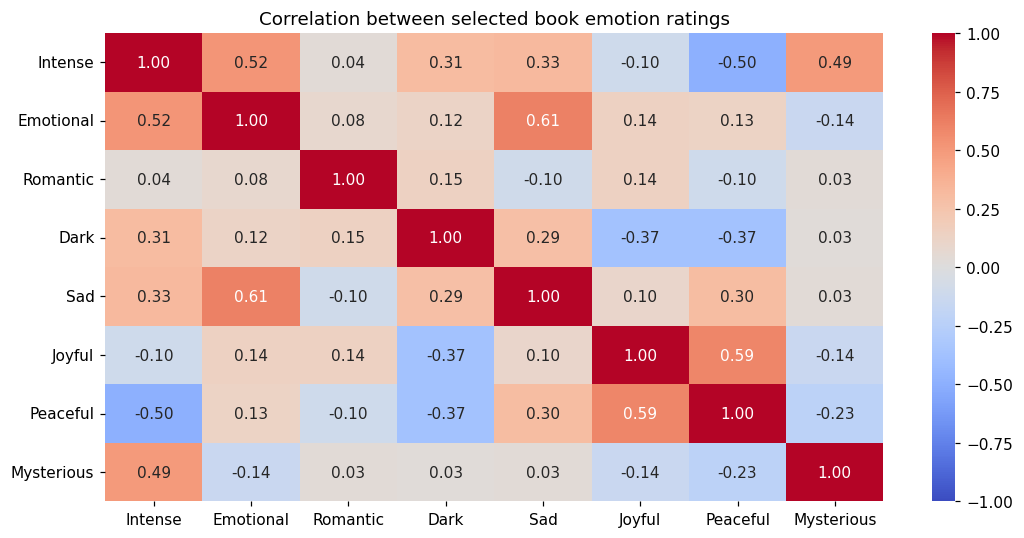

In [8]:
# Use eight emotions to keep the relationship chart readable.
selected_moods = ['Intense', 'Emotional', 'Romantic', 'Dark', 'Sad', 'Joyful', 'Peaceful', 'Mysterious']
# Compute correlations from the original ratings, not the derived binary targets.
book_correlation = books[selected_moods].corr()
# Annotate each square with its correlation value.
sns.heatmap(book_correlation, annot=True, fmt='.2f', cmap='coolwarm', center=0, vmin=-1, vmax=1)
plt.title('Correlation between selected book emotion ratings')
finish_chart('book_emotion_correlation.png')

### Interpretation and Conclusion

The strongest positive correlation shown is **Emotional–Sad (0.61)**: readers tended to give these emotions higher ratings together. The strongest negative relationship is **Intense–Peaceful (-0.50)**, so those ratings tended to move in opposite directions. This supports treating the problem as multi-label rather than forcing each book into one exclusive emotion. However, these are correlations between targets, not proof that description words predict them. With only 15 books, a few responses can noticeably change the correlations.

### Song Emotion Distribution

I count how often each selected emotion appears in the song table. This helps identify whether the music collection offers enough examples of each label. These counts describe the assigned annotations, not an objective measurement of feelings in the recordings.

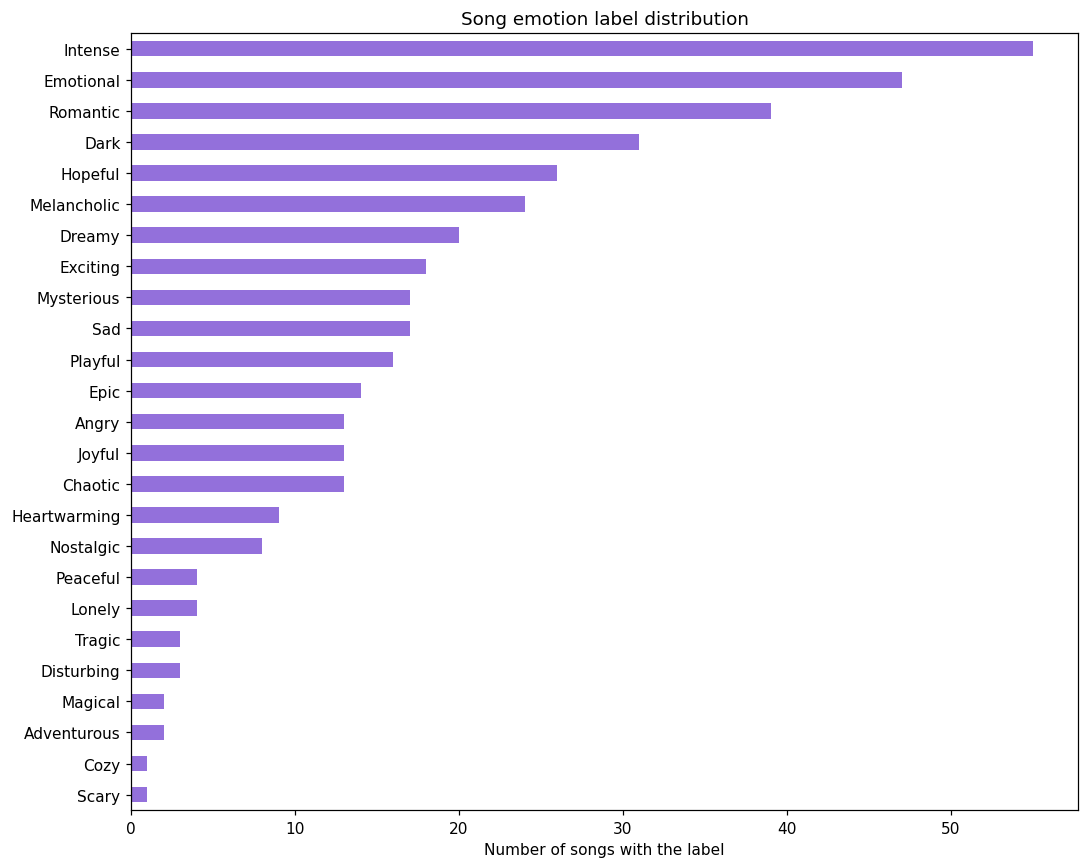

In [9]:
# Count each selected label across all song emotion lists.
song_emotion_counts = pd.Series([label for labels in songs['label_list'] for label in labels])
# Include all 25 emotions, even if a label has zero occurrences.
song_emotion_counts = song_emotion_counts.value_counts().reindex(MOODS, fill_value=0)
song_emotion_counts.sort_values().plot.barh(color='mediumpurple', figsize=(10, 8))
plt.xlabel('Number of songs with the label')
plt.title('Song emotion label distribution')
finish_chart('song_emotion_distribution.png')

### Interpretation and Conclusion

The most common song labels are **Intense, Emotional, Romantic**. The least represented are **Scary, Cozy, Adventurous**. This imbalance gives the classifiers many more examples of common emotions. A model can consequently miss rare labels while still making many correct negative decisions. Precision, recall and F1 are included so that performance is not judged from accuracy alone. These counts describe the assigned labels, whose quality still affects the results.

### Comparing Emotion Frequency in Books and Songs
This visualization compares how common each emotion is in the two datasets. For books, an emotion counts when its rating is 4 or 5. For songs, it counts when the emotion appears in the selected labels.

I use percentages because the datasets contain different numbers of records: 15 books and 80 songs. Song labels indicate selected emotions, rather than measured intensity scores.

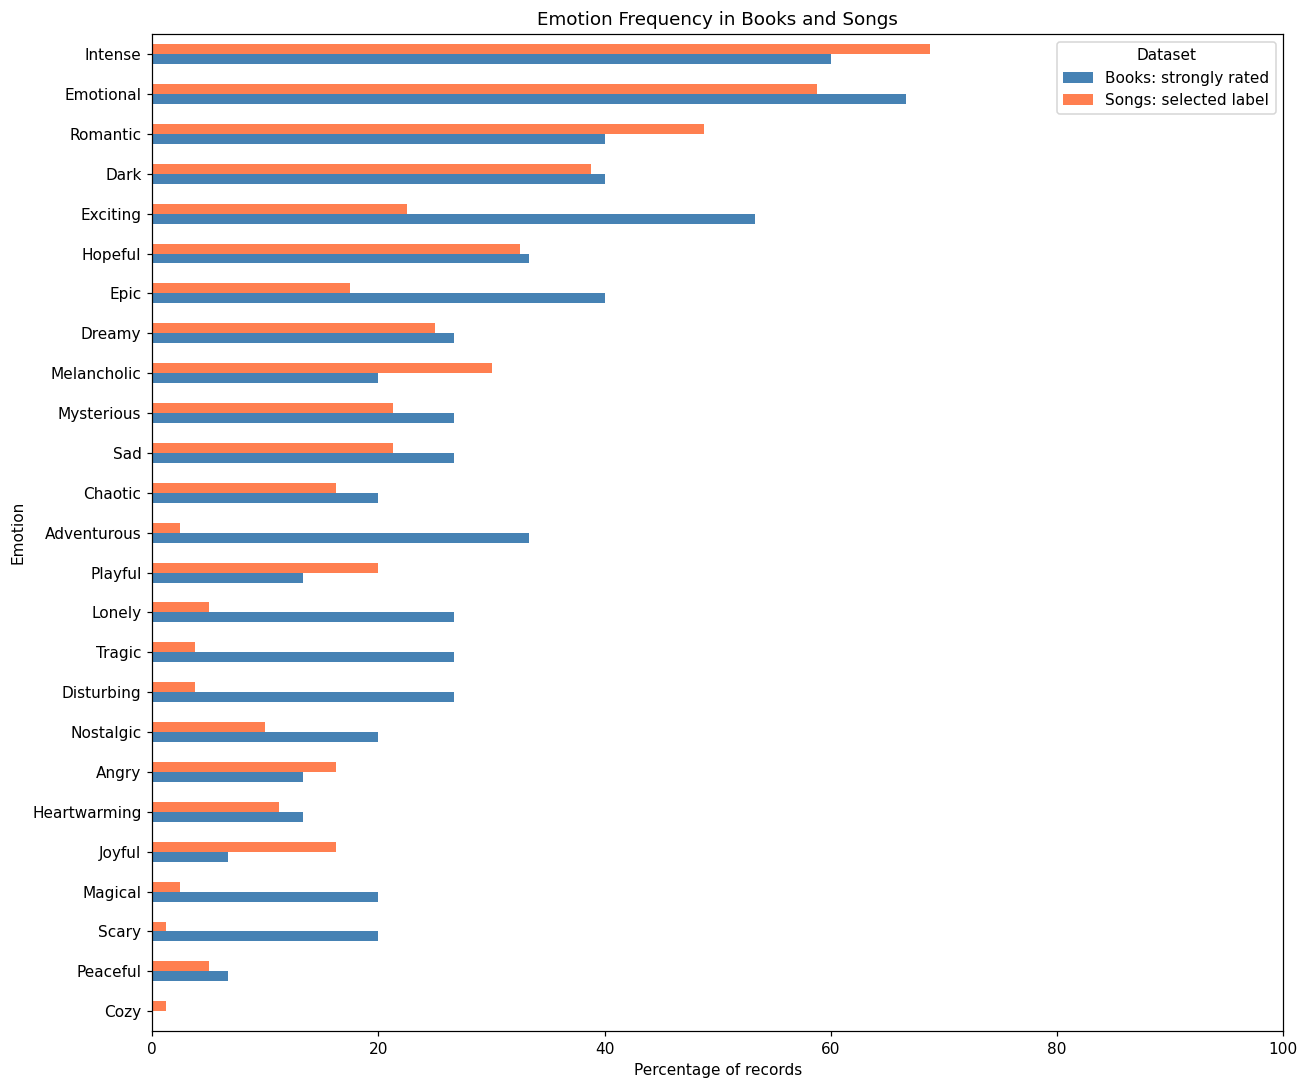

In [10]:
# Calculate the percentage of books strongly rated for each emotion.
book_frequency = (books[MOODS] >= 4).mean() * 100

# Count how many songs contain each emotion label.
song_counts = (
    songs["label_list"]
    .explode()
    .value_counts()
    .reindex(MOODS, fill_value=0)
)

# Convert song counts into percentages for a fair comparison.
song_frequency = song_counts / len(songs) * 100

# Combine both frequency profiles using the same emotion names.
emotion_comparison = pd.DataFrame({
    "Books: strongly rated": book_frequency,
    "Songs: selected label": song_frequency
})

# Sort the emotions so the most common appear near the top.
order = emotion_comparison.mean(axis=1).sort_values().index

# Display the two percentages beside each other.
emotion_comparison.loc[order].plot.barh(
    figsize=(12, 10),
    color=["steelblue", "coral"]
)

plt.title("Emotion Frequency in Books and Songs")
plt.xlabel("Percentage of records")
plt.ylabel("Emotion")
plt.xlim(0, 100)
plt.legend(title="Dataset")
plt.tight_layout()
plt.show()

### Interpretation and Conclusion
Both datasets emphasize Emotional and Intense. Emotional is strongly rated in 66.7% of books and selected for 58.8% of songs, while Intense appears in 60.0% of books and 68.8% of songs. This shared coverage gives the system more opportunities to match books and songs with these feelings.

However, some emotions are unevenly represented. Adventurous is strongly rated in 33.3% of books, but selected for only 2.5% of songs. Books with that mood may therefore have fewer suitable songs available. Common labels may also dominate model predictions and recommendations. Adding songs for underrepresented emotions would improve the balance of the dataset.

## Audio Feature Preparation

### Why this step is needed
An MP3 is a long sequence of sound samples. The classifiers in this project cannot directly compare an MP3 with a word such as Romantic or Dark. I first turn a short part of each recording into **four numerical measurements**. The model then learns whether recordings with similar measurements tend to share emotion labels in the training data.

Librosa performs the measurements. **It does not assign the emotion labels or understand the song's meaning.** The labels come from the song table. This separation between features (X) and targets (y) is important: the model must learn a relationship between them.

### What the four features describe

| Feature | How to interpret it | Why it may help / what it cannot tell us |
|---|---|---|
| Tempo | Estimated beats per minute | Faster songs may sound energetic or exciting, but speed alone cannot distinguish happy excitement from anger. Beat estimates can also be inaccurate. |
| Energy (RMS) | Average strength of the sound signal | It may help distinguish gentle from forceful recordings. Recording volume and mastering also affect it, so it is not a direct measure of emotional intensity. |
| Brightness (spectral centroid) | Where the sound's frequency content is concentrated, measured in Hz | It describes timbre: a higher value often corresponds to a brighter sound. It does not directly mean happier or more romantic. |
| Zero-crossing rate | How often the waveform changes from positive to negative or back | It provides a simple indication of noisiness/timbre. It may help separate sounds, but does not explain lyrics or narrative meaning. |

I use four features because they are small enough to inspect and explain. They are a starting point, not a complete representation of musical emotion. The experiment tests whether they contain enough useful information for these classifiers.

### What the code does, step by step
1. Load a **30-second excerpt starting 20 seconds into the file**. This reduces processing time and may skip some video introductions. The same rule is applied to every song.
2. Analyze the excerpt as **mono** rather than separate left/right channels.
3. Resample it to **22,050 samples per second**, giving every analyzed excerpt the same sampling rate. The original MP3 is not changed.
4. Calculate the four measurements and store **one row per song**, identified by `track_id`.
5. Save the feature table to a CSV so it can be reused. If the audio or extraction settings change, delete this cache and extract again.

Later, I scale the features using **training data only**, because Logistic Regression is sensitive to feature scales and the features have different units. At this stage, I only extract measurements; I do not train a classifier.

### What this helps me learn
This step demonstrates feature engineering: choosing manageable numerical descriptions of raw data. It also shows a limitation of the project. Mood can depend on lyrics, voice, listener interpretation and changes across a full song. Four measurements from one excerpt may fail to capture those factors, which can help explain weak testing performance.

In [11]:
# These four columns will be the inputs to the song classifiers.
FEATURE_COLUMNS = ['tempo', 'energy', 'brightness', 'zero_crossing_rate']
feature_path = DATA / 'simple_audio_features.csv'

# Reuse the saved measurements to avoid decoding the same music on every run.
if feature_path.exists():
    audio_features = pd.read_csv(feature_path)
    print('Loaded previously extracted features.')
else:
    feature_rows = []
    for number, row in enumerate(songs.itertuples(), start=1):
        # Read 30 seconds after the first 20 seconds; standardize analysis rate/channels.
        y, sr = librosa.load(DATA / row.audio_file, sr=22050, mono=True,
                             offset=20, duration=30)

        # Each feature is summarized as one number for this song.
        feature_rows.append({
            'track_id': row.track_id,
            'tempo': float(librosa.feature.tempo(y=y, sr=sr)[0]),
            'energy': float(librosa.feature.rms(y=y).mean()),
            'brightness': float(librosa.feature.spectral_centroid(y=y, sr=sr).mean()),
            'zero_crossing_rate': float(librosa.feature.zero_crossing_rate(y).mean())
        })
        # Report progress while extracting the collection.
        if number % 10 == 0:
            print(f'Processed {number}/{len(songs)} songs')

    # Build and save one row per song for later modeling.
    audio_features = pd.DataFrame(feature_rows)
    audio_features.to_csv(feature_path, index=False)

# Stop if the cache has duplicate/missing songs or unusable numerical values.
assert audio_features['track_id'].is_unique
assert set(audio_features['track_id']) == set(songs['track_id'])
assert np.isfinite(audio_features[FEATURE_COLUMNS].to_numpy()).all()
display(audio_features.head())

Loaded previously extracted features.


,track_id,tempo,energy,brightness,zero_crossing_rate
0,song_001,161.499023,0.307457,1622.975995,0.050994
1,song_002,86.132812,0.215194,2234.772720,0.092736
2,song_003,123.046875,0.120683,1765.603857,0.064222
3,song_004,135.999178,0.143371,1657.197022,0.068147
4,song_005,112.347147,0.234678,1370.793410,0.045488


### Correlation Between Audio Features

The next heatmap shows how the four audio features relate to each other. Strong correlations can mean two features contain some similar information. They do not directly prove that a feature predicts an emotion.

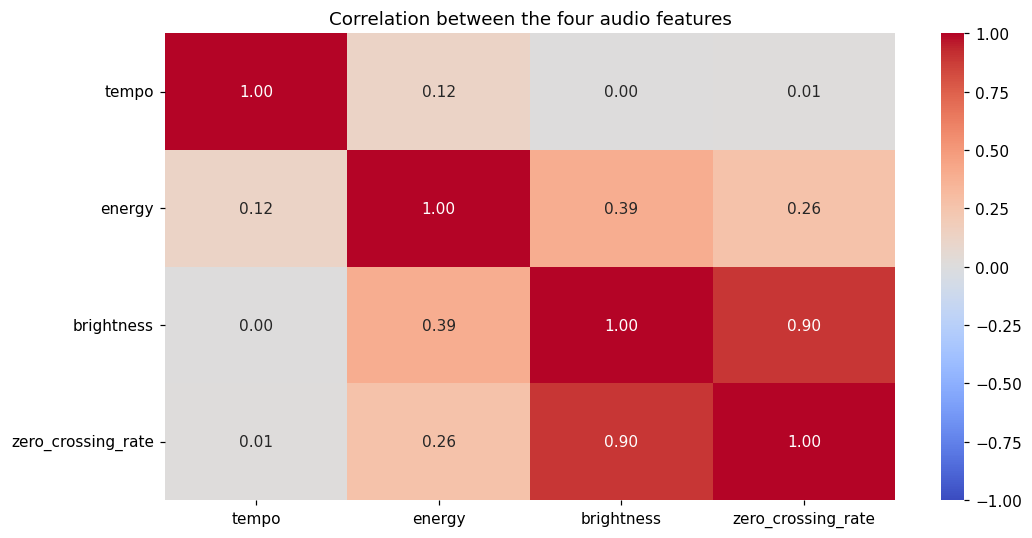

In [12]:
# Compare the four extracted features with each other.
audio_correlation = audio_features[FEATURE_COLUMNS].corr()
# Values near +1 or -1 indicate a strong relationship in this sample.
sns.heatmap(audio_correlation, annot=True, fmt='.2f', cmap='coolwarm', center=0, vmin=-1, vmax=1)
plt.title('Correlation between the four audio features')
finish_chart('audio_feature_correlation.png')

### Interpretation and Conclusion

The strongest feature relationship is **brightness–zero_crossing_rate (0.90)**. These measurements therefore contain overlapping information about the recordings. For Logistic Regression, strongly related features contain overlapping information and can make individual feature weights harder to interpret. I keep all four for this first simple experiment, while recognizing that more columns do not necessarily add more independent information. This heatmap compares features with features; it does not show that either one reliably predicts an emotion.

## EDA Conclusion

The book ratings and song labels are unevenly distributed. Emotional, Intense and Exciting have high average book ratings, while the song collection frequently uses Intense, Emotional and Romantic. This provides more examples of some emotions than others, which can influence what the classifiers learn and what they miss.

The book correlation chart shows that some ratings occur together, supporting a multi-label task. The strong relationship between audio brightness and zero-crossing rate shows that the four features do not contain completely independent information. More features would not automatically mean more useful evidence.

These observations support starting with a small, explainable model comparison. The main challenges are limited examples, uneven label coverage and subjective annotations. EDA helps understand these problems; validation and testing are still needed to measure prediction performance.

## Modeling Approach

I train one classification pipeline for book descriptions and another for song audio. The book input is TF-IDF text features; the song input is the four Librosa measurements. Both predict the same emotion vocabulary, using their own target definitions.

### Why This Approach

Logistic Regression is a straightforward baseline for both pipelines. Linear SVM provides a comparison for text, and Random Forest provides a comparison for audio. One-vs-Rest fits a separate yes/no classifier for each emotion where needed, allowing multiple emotions per record.

I keep the settings fixed and use validation F1 to choose between candidates. This avoids making the project more complicated with a large search. The final test set is used for reporting after selection. For books, rare labels and only ten training examples may make reliable learning impossible for some emotions.

## Models Used

| Pipeline | Features | Baseline | Comparison |
|---|---|---|---|
| Book emotion classification | TF-IDF | One-vs-Rest Logistic Regression | One-vs-Rest Linear SVM |
| Song emotion classification | Four Librosa features | One-vs-Rest Logistic Regression | Random Forest |

These are the classifier options discussed in the earlier project conversations. Sentence embeddings remain a possible later iteration and are not included in this simple version.

## Evaluation Metrics

Precision, recall and micro-F1 describe the label predictions. Exact-match accuracy checks whether every label decision for a record is correct, so it is stricter. I select the model with the higher **validation micro-F1**, then report both candidates' training, validation and testing results without test-based retuning.

Training/testing charts show whether performance drops on unseen examples. Confusion matrices for Dark explain true positives, true negatives, false positives and false negatives for one emotion. A matrix for one emotion does not replace the overall multi-label measures.

## Training, Validation and Testing Split

The training set fits the models. The validation set helps choose between the two models. The test set is used after that choice to report performance.

I first reserve 20% for testing. I then take one eighth of the remaining 80% for validation: 80% × 1/8 = 10%. The rest is training.

For **80 songs**, this gives exactly **56 training, 8 validation, 16 testing**. For **15 books**, exact percentages are impossible because a book cannot be divided. Scikit-learn rounds this to **10 training, 2 validation, 3 testing** (approximately 67%, 13%, 20%).

I do not change settings after inspecting test scores. This simple random split is suitable for demonstrating the workflow, but does not test generalization to completely unseen artists/authors separately.

In [13]:
# Reserve 20% of books as the untouched test set.
book_train, book_temp_test = train_test_split(books, test_size=0.20, random_state=SEED)
# One eighth of the remaining 80% gives approximately 10% validation.
book_train, book_validation = train_test_split(book_train, test_size=0.125, random_state=SEED)
book_test = book_temp_test

# Join song features by track_id, so rows do not depend on accidental file order.
song_model_data = songs.merge(audio_features, on='track_id', validate='one_to_one')
# Apply the same 70/10/20 procedure to the songs.
song_train, song_test = train_test_split(song_model_data, test_size=0.20, random_state=SEED)
song_train, song_validation = train_test_split(song_train, test_size=0.125, random_state=SEED)

# Display the actual integer split sizes and save them.
split_sizes = pd.DataFrame({
    'Dataset': ['Books', 'Songs'],
    'Training': [len(book_train), len(song_train)],
    'Validation': [len(book_validation), len(song_validation)],
    'Testing': [len(book_test), len(song_test)]
})
display(split_sizes)
split_sizes.to_csv(TABLES / 'split_sizes.csv', index=False)

# Confirm that a record never appears in two different splits.
assert set(book_train.index).isdisjoint(book_validation.index)
assert set(book_train.index).isdisjoint(book_test.index)
assert set(book_validation.index).isdisjoint(book_test.index)
assert set(song_train.track_id).isdisjoint(song_validation.track_id)
assert set(song_train.track_id).isdisjoint(song_test.track_id)
assert set(song_validation.track_id).isdisjoint(song_test.track_id)

,Dataset,Training,Validation,Testing
0,Books,10,2,3
1,Songs,56,8,16


## Book Model Training
### Preparing text features and classification targets

TF-IDF converts descriptions into word-weight features. I fit the vocabulary on training descriptions only and use that same vocabulary for validation and testing. No title, author or genre is used as a prediction input.

The original 1–5 ratings are converted into **separate training targets**: 4–5 → 1 (strongly present), 1–3 → 0 (not strongly present). I choose this threshold because 4 is defined as strongly present in the questionnaire. This is a fixed project decision, not a threshold chosen to improve test scores.

A book can have several strongly rated emotions, so it is not assigned one exclusive class. The target has 25 columns, one per emotion. This loses the difference between scores 4 and 5 for classification, but the original rating table is preserved for EDA and known-book matching.

In [14]:
# Learn the text vocabulary from training books only.
tfidf = TfidfVectorizer(max_features=500)
X_book_train = tfidf.fit_transform(book_train['description'])

# Apply the fitted vocabulary; do not learn new words from validation/test data.
X_book_validation = tfidf.transform(book_validation['description'])
X_book_test = tfidf.transform(book_test['description'])

# Derive classification targets without changing the original rating columns.
# 1 means rating >= 4; 0 means rating below 4, NOT an absent emotion.
y_book_train = (book_train[MOODS] >= 4).astype(int)
y_book_validation = (book_validation[MOODS] >= 4).astype(int)
y_book_test = (book_test[MOODS] >= 4).astype(int)

# Inspect how many positive examples each emotion has in the training set.
print('Training text features:', X_book_train.shape)
display(y_book_train.sum().to_frame('Strong examples in training'))

Training text features: (10, 279)


,Strong examples in training
Intense,5
Exciting,5
Chaotic,2
Playful,0
Adventurous,4
Epic,3
Heartwarming,1
Disturbing,2
Emotional,6
Peaceful,1


### Book Classifier Comparison

I compare the two text classifiers discussed in the project plan: **Logistic Regression** as the baseline and **Linear SVM** as the comparison. Both learn a weighted relationship between TF-IDF word features and the strong/not-strong targets. Logistic Regression estimates a probability for a label; Linear SVM learns a separating boundary and supplies a decision score. Despite its name, Logistic Regression is a classification model.

I wrap each model in **One-vs-Rest**. This fits one yes/no classifier for each of the 25 emotions, allowing several emotions to be predicted for one book. If an emotion has no positive training examples, it cannot be learned as a positive class; Scikit-learn uses a constant result for that output. The warning about a label missing from training describes this data limitation.

I use validation **micro-F1** to choose between the models. Precision measures how many predicted positives are correct; recall measures how many actual positives were found; F1 balances both. Micro combines the label decisions before calculating the score. Exact-match accuracy requires the complete predicted emotion set to match. No parameters or thresholds are adjusted after looking at the test results.

In [15]:
# One-vs-Rest trains one yes/no classifier per emotion.
# These are the two text classifiers discussed in the project plan.
book_models = {
    'Logistic Regression': OneVsRestClassifier(LogisticRegression(max_iter=1000, random_state=SEED)),
    'Linear SVM': OneVsRestClassifier(LinearSVC(dual=True, max_iter=5000, random_state=SEED))
}

# Fit on training books and compare predictions on validation books only.
book_validation_rows = []
for name, model in book_models.items():
    model.fit(X_book_train, y_book_train)
    prediction = model.predict(X_book_validation)
    book_validation_rows.append({
        'Model': name,
        'Validation micro-F1': f1_score(y_book_validation, prediction,
                                       average='micro', zero_division=0)
    })

# Choose the higher validation F1 before looking at testing results.
book_validation_results = pd.DataFrame(book_validation_rows)
display(book_validation_results)
best_book_name = book_validation_results.loc[
    book_validation_results['Validation micro-F1'].idxmax(), 'Model']
best_book_model = book_models[best_book_name]
print('Selected using validation micro-F1:', best_book_name)

sklearn\multiclass.py:87: UserWarning: Label not 3 is present in all training examples.
  warnings.warn(
sklearn\multiclass.py:87: UserWarning: Label not 14 is present in all training examples.
  warnings.warn(
sklearn\multiclass.py:87: UserWarning: Label not 22 is present in all training examples.
  warnings.warn(
sklearn\multiclass.py:87: UserWarning: Label not 3 is present in all training examples.
  warnings.warn(
sklearn\multiclass.py:87: UserWarning: Label not 14 is present in all training examples.
  warnings.warn(
sklearn\multiclass.py:87: UserWarning: Label not 22 is present in all training examples.
  warnings.warn(


,Model,Validation micro-F1
0,Logistic Regression,0.285714
1,Linear SVM,0.285714


Selected using validation micro-F1: Logistic Regression


### Book Model Performance

The choice above uses validation F1. I now report both models on the three splits, using the same measures. I do not switch the chosen model or change settings after inspecting testing results. Comparing training and testing helps reveal whether the classifier mainly remembers the small training sample.

In [16]:
# Collect the same four classification measures for every model and split.
book_results_rows = []
for name, model in book_models.items():
    for split_name, X, y in [
        ('Training', X_book_train, y_book_train),
        ('Validation', X_book_validation, y_book_validation),
        ('Testing', X_book_test, y_book_test)
    ]:
        # Predict 25 strong/not-strong emotion decisions for each book.
        prediction = model.predict(X)
        book_results_rows.append({
            'Model': name, 'Split': split_name,
            'Precision': precision_score(y, prediction, average='micro', zero_division=0),
            'Recall': recall_score(y, prediction, average='micro', zero_division=0),
            'F1': f1_score(y, prediction, average='micro', zero_division=0),
            'Exact-match accuracy': accuracy_score(y, prediction)
        })

# Display and save the measured results; none are manually entered.
book_results = pd.DataFrame(book_results_rows)
display(book_results.round(3))
book_results.to_csv(TABLES / 'book_model_performance.csv', index=False)

,Model,Split,Precision,Recall,F1,Exact-match accuracy
0,Logistic Regression,Training,0.857,0.321,0.468,0.0
1,Logistic Regression,Validation,0.750,0.176,0.286,0.0
2,Logistic Regression,Testing,0.778,0.241,0.368,0.0
3,Linear SVM,Training,1.000,1.000,1.000,1.0
4,Linear SVM,Validation,0.750,0.176,0.286,0.0
5,Linear SVM,Testing,0.700,0.241,0.359,0.0


### Book Training Versus Testing Performance

This chart compares micro-F1, where higher is better. A much higher training score suggests that patterns learned from those ten books do not transfer equally well to new books. With only three testing books, the size of the gap is also sensitive to which books were selected.

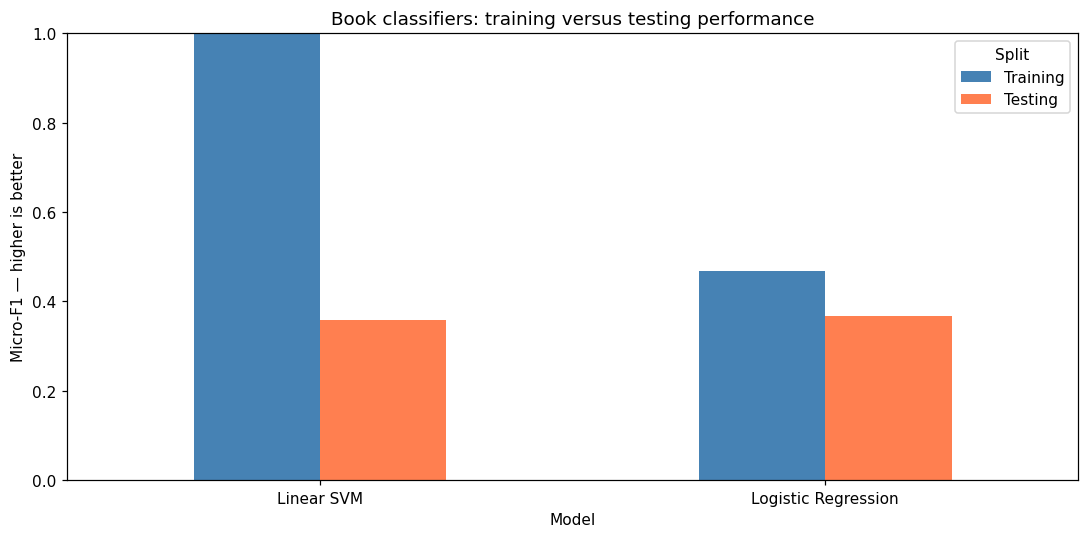

In [17]:
# Arrange the results so each model has a training bar and a testing bar.
book_chart = book_results.pivot(index='Model', columns='Split', values='F1')
book_chart[['Training', 'Testing']].plot.bar(color=['steelblue', 'coral'], rot=0)
plt.ylim(0, 1)
plt.ylabel('Micro-F1 — higher is better')
plt.title('Book classifiers: training versus testing performance')
finish_chart('book_training_testing.png')

### Interpretation of Book Results

The book candidates tie on validation micro-F1 (0.286); the listed baseline **Logistic Regression** is retained as the tie-break. Its micro-F1 changes from **0.468 in training** to **0.368 in testing**. Linear SVM has perfect training F1 but substantially lower testing F1, showing that fitting the training examples does not establish generalization. The training books contain no strongly rated examples of **Playful, Cozy, Angry**, so those positive labels cannot be learned from this split. The results support discussing overfitting and limited label coverage rather than claiming accurate book emotion recognition. Only three test books make the estimate especially uncertain.

### Book Confusion Matrix: Dark

This matrix examines one of the 25 book outputs. Here, Dark=1 means the original questionnaire rating was 4 or 5. The rows are the observed strong/not-strong labels and the columns are the predicted labels. True positives and negatives are correct decisions; false positives over-predict strong Dark, while false negatives miss it. With only three test books, each cell represents very few examples.

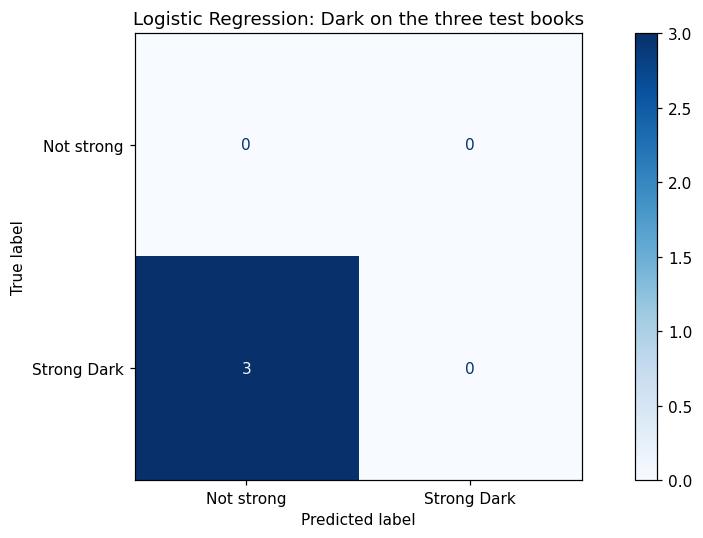

In [18]:
# Predict the held-out books with the validation-selected classifier.
book_test_prediction = best_book_model.predict(X_book_test)

# Inspect the Dark output as one simple example of classification mistakes.
book_dark_index = MOODS.index('Dark')
book_dark_matrix = confusion_matrix(
    y_book_test.iloc[:, book_dark_index],
    book_test_prediction[:, book_dark_index], labels=[0, 1])
ConfusionMatrixDisplay(book_dark_matrix, display_labels=['Not strong', 'Strong Dark']).plot(
    cmap='Blues', values_format='d')
plt.title(f'{best_book_name}: Dark on the three test books')
finish_chart('book_dark_confusion_matrix.png')

### Interpretation and Conclusion

All three books in the test set were rated strongly Dark, but the model failed to identify Dark for any of them. These are three false negatives: the emotion should have been predicted, but it was missed. There were no true positives because none were correctly identified as Dark. There were also no true or false negatives involving a correct “not strongly Dark” label, because every test book was strongly Dark. This shows poor detection of Dark in this small test set, but three books are not enough to judge performance on books generally.

## Song Model Training
### Preparing the features and labels

A song can have several labels. I encode the existing lists into the same 25-column vocabulary: 1 means the label was selected, 0 means it was not selected. This predicts the annotation lists; it does not prove an unselected feeling is absent.

The four features have very different units. Scaling prevents differences in numerical units from making the Logistic Regression baseline harder to fit or interpret. I learn the mean and standard deviation from training songs only, then apply that transformation to every split. Random Forest does not require scaling, but using the same scaled inputs makes this small comparison consistent.

In [19]:
# Define the label columns using the known common vocabulary.
label_encoder = MultiLabelBinarizer(classes=MOODS)
label_encoder.fit([MOODS])
# Convert each song label list into 25 selected/not-selected indicators.
y_song_train = label_encoder.transform(song_train['label_list'])
y_song_validation = label_encoder.transform(song_validation['label_list'])
y_song_test = label_encoder.transform(song_test['label_list'])

# Learn scaling only from training songs; apply it unchanged to the other splits.
scaler = StandardScaler()
X_song_train = scaler.fit_transform(song_train[FEATURE_COLUMNS])
X_song_validation = scaler.transform(song_validation[FEATURE_COLUMNS])
X_song_test = scaler.transform(song_test[FEATURE_COLUMNS])

print('Song training features:', X_song_train.shape)
print('Song training labels:', y_song_train.shape)

Song training features: (56, 4)
Song training labels: (56, 25)


### Song Classifier Comparison

I compare **One-vs-Rest Logistic Regression** as the simple baseline with **Random Forest**. Logistic Regression fits one yes/no decision per emotion using the scaled audio features. Random Forest combines many decision trees and can learn nonlinear relationships. I use 100 trees with maximum depth 5, keeping the settings fixed rather than running a large search.

Validation micro-F1 selects the model. I also report micro-precision, micro-recall and exact-match accuracy, using the same definitions as for books. The scores measure agreement with the song table's subjective labels, not objective musical emotion.

A warning that a label has only one value in training means there are no examples of the other class for that emotion. The model uses a constant output for it. This is a limitation of label coverage, not a failed notebook execution.

In [20]:
# Compare the planned Logistic Regression baseline with Random Forest.
# One-vs-Rest adapts Logistic Regression to the 25 emotion columns.
song_models = {
    'Logistic Regression': OneVsRestClassifier(LogisticRegression(max_iter=1000, random_state=SEED)),
    'Random Forest': RandomForestClassifier(n_estimators=100, max_depth=5, random_state=SEED)
}

# Fit on training songs; compare F1 on validation songs.
song_validation_rows = []
for name, model in song_models.items():
    model.fit(X_song_train, y_song_train)
    prediction = model.predict(X_song_validation)
    song_validation_rows.append({
        'Model': name,
        'Validation micro-F1': f1_score(y_song_validation, prediction, average='micro', zero_division=0)
    })

song_validation_results = pd.DataFrame(song_validation_rows)
display(song_validation_results)
# Choose the model from validation scores, before seeing test scores.
best_song_name = song_validation_results.loc[song_validation_results['Validation micro-F1'].idxmax(), 'Model']
best_song_model = song_models[best_song_name]
print('Selected using validation micro-F1:', best_song_name)

sklearn\multiclass.py:87: UserWarning: Label not 20 is present in all training examples.
  warnings.warn(


,Model,Validation micro-F1
0,Logistic Regression,0.548387
1,Random Forest,0.387097


Selected using validation micro-F1: Logistic Regression


### Song Model Performance

The following table compares the two models on the three splits. Validation is used to select the model before looking at test performance. Training/testing differences help show how well each model generalizes within this small song collection.

In [21]:
# Calculate the same classification measures for each model and split.
song_results_rows = []
for name, model in song_models.items():
    for split_name, X, y in [
        ('Training', X_song_train, y_song_train),
        ('Validation', X_song_validation, y_song_validation),
        ('Testing', X_song_test, y_song_test)
    ]:
        prediction = model.predict(X)
        song_results_rows.append({
            'Model': name, 'Split': split_name,
            'Precision': precision_score(y, prediction, average='micro', zero_division=0),
            'Recall': recall_score(y, prediction, average='micro', zero_division=0),
            'F1': f1_score(y, prediction, average='micro', zero_division=0),
            'Exact-match accuracy': accuracy_score(y, prediction)
        })

# Keep a table of the measured results for the written comparison.
song_results = pd.DataFrame(song_results_rows)
display(song_results.round(3))
song_results.to_csv(TABLES / 'song_model_performance.csv', index=False)

,Model,Split,Precision,Recall,F1,Exact-match accuracy
0,Logistic Regression,Training,0.678,0.354,0.465,0.000
1,Logistic Regression,Validation,0.773,0.425,0.548,0.000
2,Logistic Regression,Testing,0.636,0.350,0.452,0.000
3,Random Forest,Training,0.958,0.729,0.828,0.214
4,Random Forest,Validation,0.545,0.300,0.387,0.000
5,Random Forest,Testing,0.581,0.312,0.407,0.000


### Song Training Versus Testing Performance

This chart compares micro-F1 for training and testing. Higher is better. A much higher training score suggests the model has learned patterns that do not transfer equally well to unseen songs.

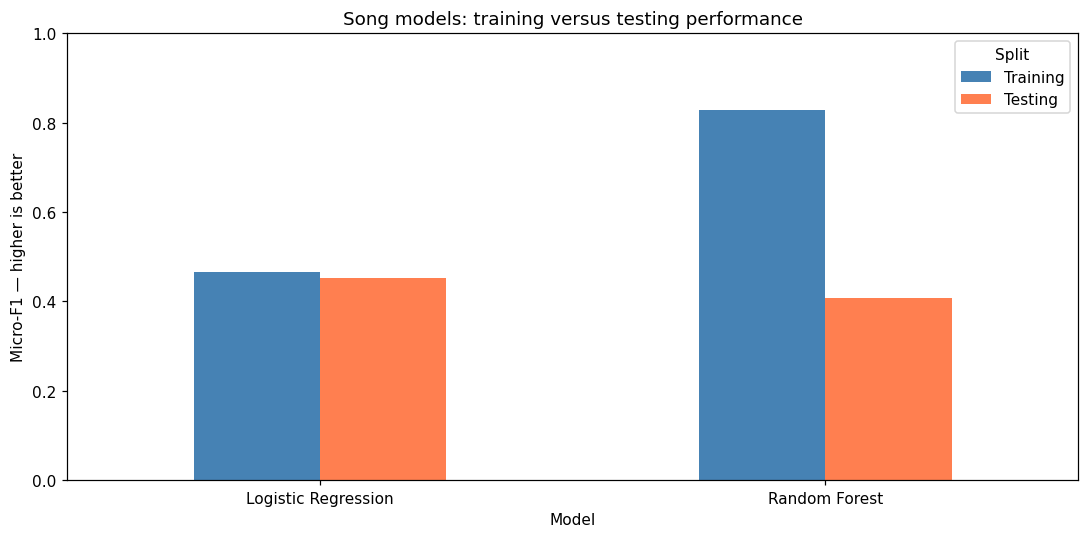

In [22]:
# Display training and testing F1 side by side for each classifier.
song_chart = song_results.pivot(index='Model', columns='Split', values='F1')
song_chart[['Training', 'Testing']].plot.bar(color=['steelblue', 'coral'], rot=0)
plt.ylim(0, 1)
plt.ylabel('Micro-F1 — higher is better')
plt.title('Song models: training versus testing performance')
finish_chart('song_training_testing.png')

### Interpretation of Song Results

Validation selected **Logistic Regression**. Its training micro-F1 is **0.465**, compared with **0.452 in testing**. Random Forest fits the training songs more closely but has lower validation and testing F1 than the baseline in this run. The baseline has a smaller training/testing gap than Random Forest, but its modest testing F1 still limits its usefulness. A small gap alone is not proof that the emotion predictions are accurate. Exact-match accuracy is particularly strict: one wrong label makes the whole song set incorrect. Adding reliable labels and more varied examples is a more useful next step than interpreting a higher training score as success.

### Song Confusion Matrix: Dark

A confusion matrix shows correct and incorrect classification decisions. Because songs have several labels, there is not one ordinary multiclass matrix for the whole task. I show **Dark** as one clear example:

- True negative: Dark was not selected and the model did not predict it.
- False positive: the model predicted Dark when it was not selected.
- False negative: Dark was selected but the model missed it.
- True positive: Dark was selected and predicted.

Both pipelines use classification. Their performance tables report overall multi-label measures, while each confusion matrix examines one emotion.

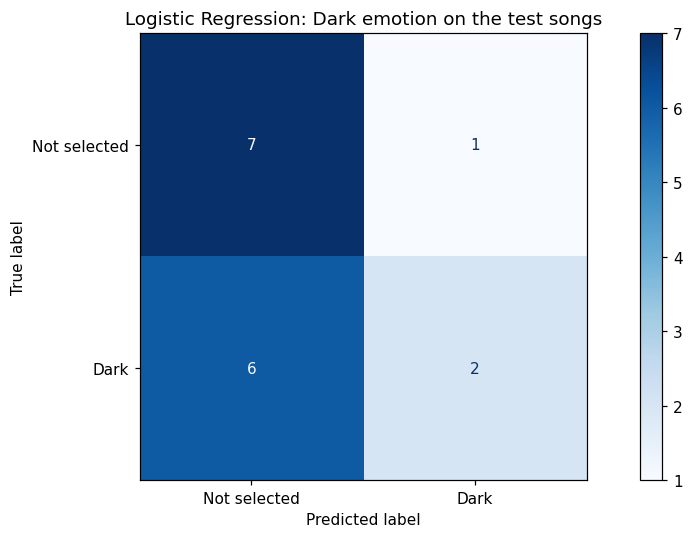

In [23]:
# Use only held-out songs for this confusion matrix.
song_test_prediction = best_song_model.predict(X_song_test)
# Select the Dark output column; label order is the shared MOODS list.
dark_index = MOODS.index('Dark')
# Force both 0 and 1 axes even if one class has no examples in this small set.
dark_matrix = confusion_matrix(y_song_test[:, dark_index], song_test_prediction[:, dark_index], labels=[0, 1])
ConfusionMatrixDisplay(dark_matrix, display_labels=['Not selected', 'Dark']).plot(cmap='Blues', values_format='d')
plt.title(f'{best_song_name}: Dark emotion on the test songs')
finish_chart('song_dark_confusion_matrix.png')

### Interpretation and Conclusion

For Dark, there are **2 true positives**, **7 true negatives**, **1 false positives**, and **6 false negatives** among the held-out songs. False negatives show missed target labels; false positives show over-prediction. This example helps explain the errors but does not summarize every emotion. The matrix is evaluated against the song annotations, whose subjectivity limits what these scores establish.

## Connecting Book Emotions to Songs

The classification plan needs a distinction between **known ratings** and **model scores**:

- For a book already in the dataset, I can use its original 1–5 ratings as weights. Matching Romantic=5 contributes more than matching Sad=2, as requested.
- For a new description, a classifier predicts labels and supplies a score for each emotion. Those scores can act as weights, but they are **not predicted questionnaire ratings** and are not guaranteed to be well-calibrated probabilities.

The song classifier predicts the labels for each track. I sum the book weights for those labels, then divide by the sum of the book's weights. A larger result means more of the book's weighted emotion profile is covered. It is a ranking score, not recommendation accuracy.

The following example shows the complete workflow. I enter a new book description, predict its emotions, and compare those emotion scores with the predicted song labels. Songs with stronger matches appear higher in the list. This demonstrates that the two models can be connected to produce recommendations. However, listener feedback would be needed to evaluate whether the recommended songs actually fit the book.

In [24]:
# Enter a new description to demonstrate the two trained classification pipelines.
example_description = (
    'A young woman discovers a dangerous secret in an isolated town. '
    'She must decide who to trust while protecting someone she loves.'
)
book_features = tfidf.transform([example_description])

# Logistic Regression provides one positive-label probability per emotion.
# Linear SVM instead provides decision scores: positive means the strong class.
# Keep positive SVM scores as matching weights; do not call them probabilities.
if hasattr(best_book_model, 'predict_proba'):
    book_weights = best_book_model.predict_proba(book_features)[0]
else:
    decision_scores = best_book_model.decision_function(book_features)[0]
    book_weights = np.maximum(decision_scores, 0)

# These are classifier support scores, not 1–5 book rating predictions.
print('Emotion scores for the new description:')
display(pd.Series(book_weights, index=MOODS).sort_values(ascending=False)
        .head(5).to_frame('Classifier score'))

# For a KNOWN book, replace the weights above with this original rating profile:
# book_weights = books.loc[books['title'] == 'The Hunger Games', MOODS].iloc[0].to_numpy(float)

# Predict the song labels from the four audio features using the selected model.
all_song_features = scaler.transform(song_model_data[FEATURE_COLUMNS])
predicted_song_labels = best_song_model.predict(all_song_features)

# Higher book weights make shared song emotions contribute more to the match.
# Avoid division by zero if the book classifier gives no emotion a positive score.
if book_weights.sum() > 0:
    match_scores = (predicted_song_labels * book_weights).sum(axis=1) / book_weights.sum()
else:
    match_scores = np.zeros(len(song_model_data))
    print('No positive emotion scores: the model cannot provide a meaningful ranking.')

# Display the highest-scoring tracks, together with their predicted emotion names.
playlist = song_model_data[['song_title', 'artist', 'audio_file']].copy()
playlist['predicted_emotions'] = [
    ', '.join(MOODS[i] for i in range(len(MOODS)) if row[i] == 1)
    for row in predicted_song_labels
]
playlist['match_score'] = match_scores
playlist = playlist.sort_values('match_score', ascending=False).head(10)
display(playlist)
playlist.to_csv(TABLES / 'example_playlist.csv', index=False)

# Save the selected classifiers and the preprocessing needed to reuse them.
joblib.dump({'model': best_book_model, 'tfidf': tfidf, 'emotions': MOODS,
             'strong_rating_threshold': 4}, MODELS / 'book_model.joblib')
joblib.dump({'model': best_song_model, 'scaler': scaler, 'features': FEATURE_COLUMNS,
             'emotions': MOODS}, MODELS / 'song_model.joblib')

Emotion scores for the new description:


,Classifier score
Emotional,0.615162
Intense,0.513217
Exciting,0.508432
Adventurous,0.401328
Lonely,0.300529


,song_title,artist,audio_file,predicted_emotions,match_score
64,Skyfall,Adele,audio/065_Adele_Skyfall.mp3,"Intense, Epic, Emotional, Melancholic, Romanti...",0.380878
48,Yellow Flicker Beat,Lorde,audio/049_Lorde_Yellow_Flicker_Beat.mp3,"Intense, Epic, Emotional, Hopeful, Romantic",0.345992
27,I See Fire,Ed Sheeran,audio/028_Ed_Sheeran_I_See_Fire.mp3,"Intense, Emotional, Melancholic, Romantic, Dark",0.326568
72,Never Enough,Loren Allred,audio/073_Loren_Allred_Never_Enough.mp3,"Intense, Emotional, Melancholic, Romantic",0.292207
59,Do It for Me,Rosenfeld,audio/060_Rosenfeld_Do_It_for_Me.mp3,"Intense, Emotional, Melancholic, Romantic",0.292207
23,do the math,Dove Cameron,audio/024_Dove_Cameron_do_the_math.mp3,"Intense, Emotional, Melancholic, Romantic",0.292207
18,Atlas,Coldplay,audio/019_Coldplay_Atlas.mp3,"Intense, Emotional, Melancholic, Romantic",0.292207
13,Dancing On My Own,Calum Scott,audio/014_Calum_Scott_Dancing_On_My_Own.mp3,"Intense, Emotional, Melancholic, Romantic",0.292207
12,Just a Game,Birdy,audio/013_Birdy_Just_a_Game.mp3,"Intense, Emotional, Melancholic, Romantic",0.292207
35,I See Red,Everybody Loves an Outlaw,audio/036_Everybody_Loves_an_Outlaw_I_See_Red.mp3,"Intense, Emotional, Melancholic, Romantic",0.292207


Out[1]: ['C:\\Users\\timit\\Documents\\Codex\\2026-11-09\\https-chatgpt-com-share-6af219bc-1388\\outputs\\book-mood-reader\\models\\song_model.joblib']


## Summary

The notebook follows the complete path from collected tables to an example song list. Both pipelines use multi-label classification, and validation retains Logistic Regression for books and selects it for songs. The recorded testing micro-F1 is **0.368 for books** and **0.452 for songs**.

The training/testing comparisons show that stronger training scores do not necessarily produce stronger predictions on new records. The weighted matching calculation produces a ranked list, but the recommendations have not been independently evaluated by listeners.

## Project Evaluation

### Strengths

The project uses data I collected and organized myself. The two tables share a consistent emotion vocabulary, and the notebook explains how raw values, model inputs and classification targets differ. It includes inspection, cleaning, EDA, model comparison and a song-list demonstration rather than reporting a model score without its preparation process.

The fixed training/validation/testing split makes model selection understandable. Comparing more than one classifier shows that a more flexible model can fit training examples strongly without performing better on new examples. Code comments and written chart interpretations make the decisions easier to explain.

### Limitations and Challenges

The book sample is very small: ten training books, two validation books and three testing books. Some emotions have no positive training examples, so those positive classes cannot be learned. The 4/5 threshold also loses the distinction between those two strengths for classification, although the original ratings are retained.

Song labels include AI-assisted suggestions and subjective judgments. Four measurements from one short excerpt do not capture lyrics or every emotional change in a full recording. Live, edited or video versions may introduce additional variation. Random splits can also place the same author or artist in different sets.

The available results therefore describe this small collection and its annotations. Neither a good training score nor a high matching score proves that the system understands a book or will recommend suitable songs for everyone.

### Real-World Potential

The idea could become a simple reading companion: enter a description, inspect the predicted emotions and receive a matching song list. In its current form it is a learning prototype. More reliable labels, broader data and listener feedback are needed before claiming dependable recommendation quality.

### Next Steps and Future Improvements

I would first collect more varied books, review song labels by listening and improve coverage of rare emotions. I would check audio versions more consistently and ask readers to judge suggested book–song matches. Those steps would help identify whether the main problem is the data, the classifiers or the matching rule before adding more complex methods.

## Final Reflection

I practiced checking and cleaning two datasets, interpreting charts, converting text/audio into numerical features, and training more than one classifier. I learned that a dataset can retain numerical ratings for analysis while using a clearly defined categorical target for a classification experiment.

The training/testing comparisons show why a good training result is not enough. Precision, recall and F1 explain different types of success and failure, while confusion matrices make mistakes for one emotion easier to see. Validation helps choose a model before the final test, even though a tiny validation set makes the choice uncertain.

I also learned to separate a known book's original emotion strengths from the scores a classifier produces for new text. Both can be used as matching weights, but they are not the same quantity.

AI assistance was used for parts of data preparation, code and notebook drafting. The measured results come from executing the code. I should be able to explain the comments, decisions and limitations before presenting this work as portfolio evidence.

In [25]:
# Summarize what actually ran, rather than entering model scores manually.
chosen_book_scores = book_results[book_results.Model.eq(best_book_name)].set_index('Split')
chosen_song_scores = song_results[song_results.Model.eq(best_song_name)].set_index('Split')
summary = {
    'task_books': 'multi-label classification',
    'task_songs': 'multi-label classification',
    'book_strong_rating_threshold': 4,
    'books': len(books), 'songs': len(songs),
    'book_split': [len(book_train), len(book_validation), len(book_test)],
    'song_split': [len(song_train), len(song_validation), len(song_test)],
    'selected_book_model': best_book_name,
    'selected_song_model': best_song_name,
    'book_test_micro_F1': float(chosen_book_scores.loc['Testing', 'F1']),
    'song_test_micro_F1': float(chosen_song_scores.loc['Testing', 'F1']),
    'song_labels_reviewed_ground_truth': False
}
(TABLES / 'project_summary.json').write_text(json.dumps(summary, indent=2))
display(pd.Series(summary, name='Project summary').to_frame())

,Project summary
task_books,multi-label classification
task_songs,multi-label classification
book_strong_rating_threshold,4
books,15
songs,80
book_split,"[10, 2, 3]"
song_split,"[56, 8, 16]"
selected_book_model,Logistic Regression
selected_song_model,Logistic Regression
book_test_micro_F1,0.368421


## Resources

- My questionnaire export: `data/raw/book_moods_clean_ratings.csv`.
- My song table and downloaded audio: `data/raw/songs.xlsx` and `data/audio/`.
- Supplied F1 notebook: structure and writing reference.
- [Scikit-learn: train/test splitting](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.train_test_split.html)
- [Scikit-learn: metrics and model evaluation](https://scikit-learn.org/stable/modules/model_evaluation.html)
- [Scikit-learn: TF-IDF](https://scikit-learn.org/stable/modules/generated/sklearn.feature_extraction.text.TfidfVectorizer.html)
- [Librosa audio features](https://librosa.org/doc/0.10.2/feature.html)